# 02 — Análise de negócio: operação piloto de táxi em NYC

## 1. Contexto, objetivo e perguntas

Uma empresa de táxi está estudando uma **operação piloto em NYC** e solicitou uma análise histórica para selecionar zonas e faixas de horário que mereçam investigação comercial.

A entrega é exploratória: buscamos evidências para orientar um estudo inicial, sem calcular demanda reprimida, lucro, tamanho da frota ou viabilidade atual de entrada no mercado.

Perguntas:
1. Onde se concentram os embarques registrados?
2. Em quais dias e horários ocorre o movimento nessas zonas?
3. Como tarifa, valor total cobrado, distância e duração variam entre zonas?
4. Esses padrões se mantêm nos diferentes meses disponíveis?

**Recorte de negócio:** embarques de 01/01/2018 (inclusive) a 01/01/2019 (exclusive), conforme os parâmetros dos cinco arquivos SQL. A auditoria examina todos os anos. Ter registros nos 365 dias não comprova cobertura completa ou representatividade da cidade.

**Fluxo:** PostgreSQL → SQL versionado → resultados agregados em pandas → análise → futuro dashboard em **Streamlit**.

Não repetimos o tratamento da Silver/Gold. O notebook anterior explora a qualidade da origem; este interpreta a base tratada para uma decisão empresarial.

## 2. Preparação e conexão com o PostgreSQL

Execute com o Python da `.venv` do projeto, no WSL, com o PostgreSQL ativo e as tabelas já carregadas. É possível iniciar o notebook na raiz ou em `notebooks/`.

As credenciais são lidas de `.env.postgres`, ignorado pelo Git. Não exibimos o conteúdo do arquivo nem o objeto da conexão. As bibliotecas utilizadas já constam em `requirements.txt`.

O SQL continua em `sql/analytics/`: o notebook lê esses arquivos, evitando manter duas versões das mesmas regras. Apenas os resultados agregados chegam ao pandas.

In [1]:
%matplotlib inline

from pathlib import Path
from decimal import Decimal
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown
import psycopg
from dotenv import dotenv_values

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "sql" / "analytics").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "sql" / "analytics").is_dir():
    raise RuntimeError("Execute o notebook a partir da raiz do projeto ou de notebooks/.")

SQL_PATH = PROJECT_ROOT / "sql" / "analytics"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")


def create_connection():
    settings = dotenv_values(PROJECT_ROOT / ".env.postgres")
    required = ["POSTGRES_DB", "POSTGRES_USER", "POSTGRES_PASSWORD"]
    if any(not settings.get(name) for name in required):
        raise ValueError("Configure DB, USER e PASSWORD em .env.postgres antes de executar.")

    return psycopg.connect(
        host=settings.get("POSTGRES_HOST", "127.0.0.1"),
        port=settings.get("POSTGRES_PORT", "5432"),
        dbname=settings["POSTGRES_DB"],
        user=settings["POSTGRES_USER"],
        password=settings["POSTGRES_PASSWORD"],
        application_name="nyc_taxi_pilot_analysis",
        connect_timeout=10,
        autocommit=True,
    )


def read_query(connection, filename):
    query = (SQL_PATH / filename).read_text(encoding="utf-8")
    with connection.cursor() as cursor:
        cursor.execute(query)
        columns = [column.name for column in cursor.description]
        result = pd.DataFrame(cursor.fetchall(), columns=columns)

    # Conversão apenas para análise/gráficos; não altera os NUMERIC do banco.
    return result.map(lambda value: float(value) if isinstance(value, Decimal) else value)


def format_number(value):
    return f"{value:,.0f}".replace(",", ".")

### Carregamento das seis consultas

Uma transação **somente de leitura**, com snapshot consistente, mantém as seis consultas sobre a mesma versão dos dados. A conexão é fechada ao final, inclusive se houver erro. O limite de cinco minutos é por consulta.

O resultado com zona, dia e hora tem mais linhas, mas ainda é uma agregação pequena em comparação com a fato. Não usamos `SELECT * FROM fact_trips` nem exportamos os fatos ou as credenciais.

In [2]:
query_files = {
    "coverage": "00_data_coverage.sql",
    "monthly": "01_monthly_activity.sql",
    "zones": "02_pickup_zones.sql",
    "hourly": "03_zone_weekday_hour.sql",
    "profile": "04_zone_trip_profile.sql",
    "zone_monthly": "05_zone_monthly_activity.sql",
}

results = {}
with create_connection() as connection:
    with connection.transaction():
        connection.execute("SET TRANSACTION ISOLATION LEVEL REPEATABLE READ, READ ONLY")
        connection.execute("SET LOCAL statement_timeout = '5min'")
        for name, filename in query_files.items():
            results[name] = read_query(connection, filename)
            print(f"{filename}: {len(results[name]):,} linhas agregadas")

coverage = results["coverage"]
monthly = results["monthly"]
zones = results["zones"]
hourly = results["hourly"]
profile = results["profile"]
zone_monthly = results["zone_monthly"]
monthly["month"] = pd.to_datetime(monthly["month"])
zone_monthly["month"] = pd.to_datetime(zone_monthly["month"])

print("Consulta concluída em:", datetime.now().isoformat(timespec="seconds"))

00_data_coverage.sql: 11 linhas agregadas


01_monthly_activity.sql: 12 linhas agregadas


02_pickup_zones.sql: 259 linhas agregadas


03_zone_weekday_hour.sql: 43,512 linhas agregadas


04_zone_trip_profile.sql: 259 linhas agregadas


05_zone_monthly_activity.sql: 3,108 linhas agregadas
Consulta concluída em: 2026-10-20T15:16:12


## 3. Cobertura e validação antes das conclusões

Primeiro, verificamos se as contagens dos diferentes grãos reconciliam e se os arquivos SQL continuam usando o mesmo recorte. Uma falha interrompe a análise: não devemos montar gráficos com períodos ou denominadores diferentes.

A zona desconhecida permanece nas contagens. Ela não identifica um local para investigar, mas sua exclusão silenciosa esconderia parte da base.

In [3]:
business_year = 2018
business_coverage = coverage.loc[coverage["pickup_year"].eq(business_year)]
assert len(business_coverage) == 1, "O período de negócio não está disponível."
expected_trips = int(business_coverage.iloc[0]["trip_count"])

for name in ["monthly", "zones", "hourly", "profile", "zone_monthly"]:
    assert results[name]["trip_count"].sum() == expected_trips, f"Contagem divergente: {name}"

assert monthly["month"].dt.year.eq(business_year).all()
assert monthly["month"].nunique() == 12
assert zone_monthly["month"].dt.year.eq(business_year).all()
pd.testing.assert_series_equal(
    monthly.set_index("month")["trip_count"].sort_index(),
    zone_monthly.groupby("month")["trip_count"].sum().sort_index(),
    check_names=False,
)
assert abs(zones["share_of_dataset_pct"].sum() - 100) < 0.02
assert hourly.groupby("day_of_week")["observed_weekdays"].nunique().eq(1).all()

all_trips = int(coverage["trip_count"].sum())
outside_period = all_trips - expected_trips
unknown_trips = int(business_coverage.iloc[0]["unknown_pickup_zone_trips"])
unknown_pct = 100 * unknown_trips / expected_trips

display(coverage)
display(Markdown(
    f"**Leitura da cobertura:** {format_number(all_trips)} viagens no banco; "
    f"{format_number(expected_trips)} em 2018 e {format_number(outside_period)} fora do recorte. "
    f"Em 2018, {format_number(unknown_trips)} embarques ({unknown_pct:.2f}%) têm zona desconhecida. "
    "Os registros fora do período e os valores extremos permanecem na base; o recorte é somente analítico."
))

,pickup_year,first_pickup_date,last_pickup_date,trip_count,observed_days,unknown_pickup_zone_trips,null_fare_trips,nonpositive_fare_trips,null_total_trips,nonpositive_total_trips,max_distance_miles,max_duration_minutes
0,2001,2001-01-01,2001-01-01,2,1,0,0,0,0,0,4.67,70.00
1,2002,2002-12-31,2002-12-31,2,1,0,0,0,0,0,19.22,"1,078.87"
2,2003,2003-01-01,2003-01-01,2,1,0,0,0,0,0,12.07,"1,185.87"
3,2008,2008-12-31,2008-12-31,45,1,0,0,0,0,0,56.23,921.43
4,2009,2009-01-01,2009-01-01,51,1,0,0,0,0,0,35.97,"1,311.30"
5,2017,2017-12-31,2017-12-31,12,1,0,0,0,0,0,11.91,28.30
6,2018,2018-01-01,2018-12-31,9100757,365,140537,0,28022,0,22979,"7,655.76","5,333.85"
7,2019,2019-01-01,2019-11-21,13,12,1,0,0,0,0,13.24,540.47
8,2020,2020-08-01,2020-08-01,1,1,0,0,0,0,0,16.71,26.18
9,2029,2029-05-05,2029-05-05,1,1,0,0,0,0,0,11.51,159.70


**Leitura da cobertura:** 9.100.887 viagens no banco; 9.100.757 em 2018 e 130 fora do recorte. Em 2018, 140.537 embarques (1.54%) têm zona desconhecida. Os registros fora do período e os valores extremos permanecem na base; o recorte é somente analítico.

**Implicação para o estudo:** a análise descreve um extrato histórico, não todo o mercado. O método de seleção do extrato e sua fração do universo TLC não foram comprovados pela pipeline. A origem também não traz um campo explícito de tipo de serviço para comparar yellow, green e FHV.

As máximas de distância e duração na auditoria evidenciam por que não devemos depender apenas de médias. Não criaremos filtros adicionais para obter um resultado mais conveniente.

## 4. Movimento ao longo do ano

**Pergunta:** como o movimento registrado varia entre os meses?

Comparamos o volume e a média por dia observado. Isso evita atribuir a diferença entre meses somente à atividade quando eles têm quantidades diferentes de dias. Os denominadores são conferidos na tabela; um mês sem observação não deve ser interpretado como ausência de demanda.

,month,calendar_days,observed_days,trip_count,trips_per_observed_day,unknown_pickup_zone_trips
0,2018-01-01,31,31,675246,"21,782.13",11666
1,2018-02-01,28,28,672324,"24,011.57",10277
2,2018-03-01,31,31,934436,"30,143.10",15859
3,2018-04-01,30,30,794338,"26,477.93",12464
4,2018-05-01,31,31,840318,"27,107.03",11544
5,2018-06-01,30,30,793674,"26,455.80",10938
6,2018-07-01,31,31,691610,"22,310.00",10046
7,2018-08-01,31,31,655722,"21,152.32",8623
8,2018-09-01,30,30,723554,"24,118.47",9204
9,2018-10-01,31,31,819940,"26,449.68",12800


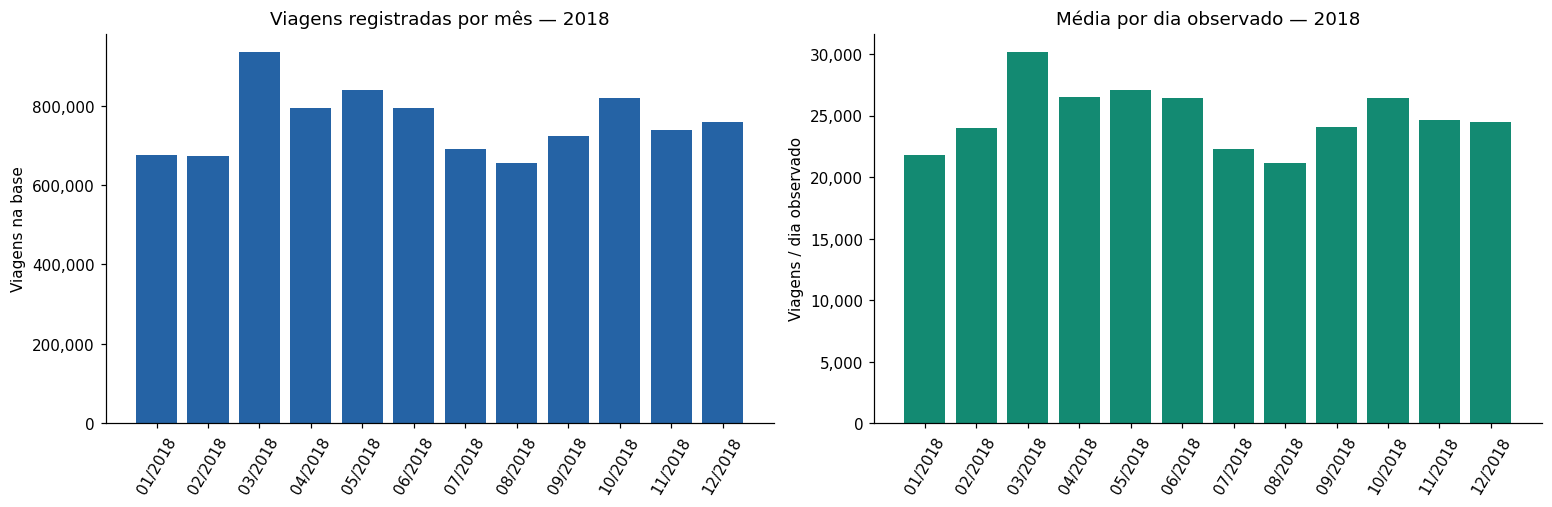

**Leitura:** a maior média diária aparece em 03/2018 (30.143 viagens/dia), e a menor em 08/2018 (21.152). Isso é variação observada neste extrato. Um único ano não comprova sazonalidade recorrente ou crescimento do mercado; a composição da fonte também pode influenciar o padrão.

In [4]:
display(monthly)

month_labels = monthly["month"].dt.strftime("%m/%Y")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
axes[0].bar(month_labels, monthly["trip_count"], color="#2563a5")
axes[0].set(title="Viagens registradas por mês — 2018", ylabel="Viagens na base")
axes[1].bar(month_labels, monthly["trips_per_observed_day"], color="#138a72")
axes[1].set(title="Média por dia observado — 2018", ylabel="Viagens / dia observado")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

highest_daily = monthly.loc[monthly["trips_per_observed_day"].idxmax()]
lowest_daily = monthly.loc[monthly["trips_per_observed_day"].idxmin()]
display(Markdown(
    f"**Leitura:** a maior média diária aparece em {highest_daily['month']:%m/%Y} "
    f"({format_number(highest_daily['trips_per_observed_day'])} viagens/dia), e a menor em "
    f"{lowest_daily['month']:%m/%Y} ({format_number(lowest_daily['trips_per_observed_day'])}). "
    "Isso é variação observada neste extrato. Um único ano não comprova sazonalidade recorrente "
    "ou crescimento do mercado; a composição da fonte também pode influenciar o padrão."
))

## 5. Onde se concentram os embarques?

**Pergunta:** quais zonas concentram o movimento registrado?

O gráfico mostra as dez zonas mapeadas com maior volume. A participação continua usando **todas** as viagens do recorte no denominador, inclusive as de zona desconhecida. `borough` identifica o grande distrito; uma zona TLC não é necessariamente um bairro administrativo.

Escolhemos as três primeiras zonas por volume para aprofundar as próximas comparações. É um critério exploratório transparente, não uma pontuação de oportunidade nem uma recomendação de entrada.

,zone_id,zone_name,borough,trip_count,share_of_dataset_pct,trips_per_observed_day
0,138,LaGuardia Airport,Queens,1981984,21.78,"5,430.09"
1,132,JFK Airport,Queens,869812,9.56,"2,383.05"
2,230,Times Sq/Theatre District,Manhattan,299952,3.30,821.79
3,161,Midtown Center,Manhattan,265593,2.92,727.65
4,162,Midtown East,Manhattan,239710,2.63,656.74
5,186,Penn Station/Madison Sq West,Manhattan,214468,2.36,587.58
6,48,Clinton East,Manhattan,206733,2.27,566.39
7,170,Murray Hill,Manhattan,190306,2.09,521.39
8,163,Midtown North,Manhattan,186510,2.05,510.99
9,236,Upper East Side North,Manhattan,180772,1.99,495.27


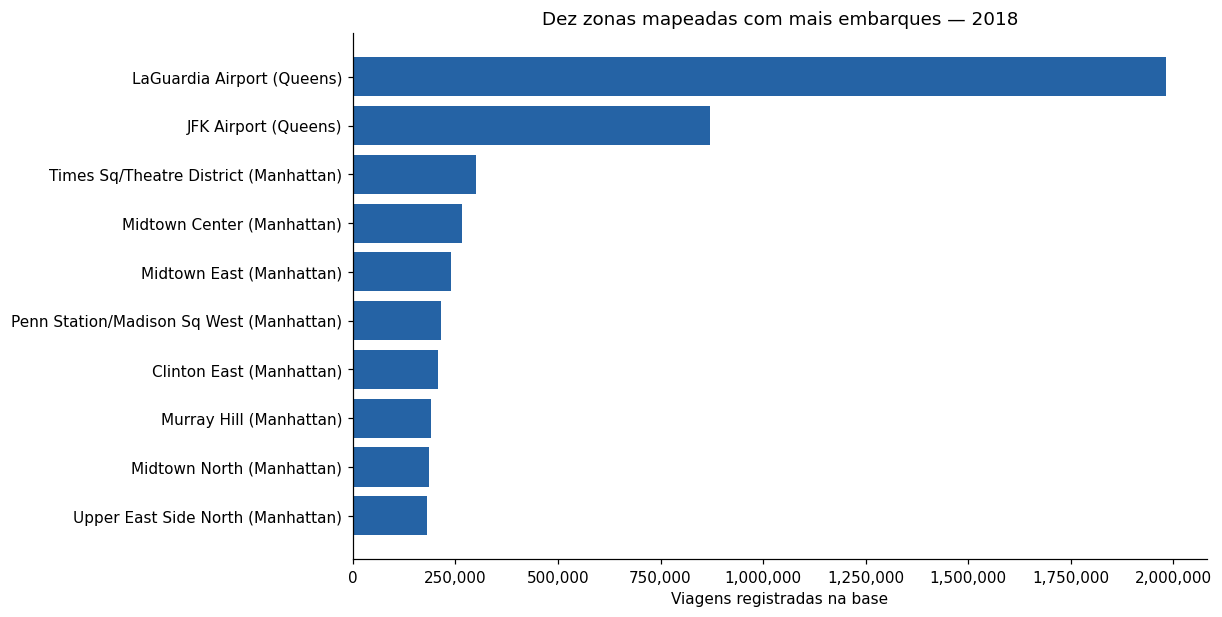

,borough,trip_count,share_of_dataset_pct
3,Manhattan,5767081,63.37
4,Queens,2985075,32.80
1,Brooklyn,182503,2.01
6,Unknown,140537,1.54
0,Bronx,23378,0.26
2,EWR,1575,0.02
5,Staten Island,608,0.01


**Leitura:** as zonas selecionadas são LaGuardia Airport, JFK Airport, Times Sq/Theatre District. Juntas concentram 34.63% das viagens do recorte. A concentração em poucos locais deve ser investigada junto à composição do extrato. Volume histórico elevado não informa oferta concorrente, tempo de espera ou demanda não atendida.

In [5]:
mapped_zones = zones.loc[zones["is_mapped_zone"]].copy()
top_zones = mapped_zones.nlargest(10, "trip_count")
candidate_zone_ids = top_zones.head(3)["zone_id"].tolist()
candidate_names = top_zones.head(3)["zone_name"].tolist()

display(top_zones[["zone_id", "zone_name", "borough", "trip_count", "share_of_dataset_pct", "trips_per_observed_day"]])

plot_zones = top_zones.sort_values("trip_count")
fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
labels = plot_zones["zone_name"] + " (" + plot_zones["borough"] + ")"
ax.barh(labels, plot_zones["trip_count"], color="#2563a5")
ax.set(title="Dez zonas mapeadas com mais embarques — 2018", xlabel="Viagens registradas na base")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

borough_activity = zones.groupby("borough", as_index=False)["trip_count"].sum()
borough_activity["share_of_dataset_pct"] = 100 * borough_activity["trip_count"] / expected_trips
display(borough_activity.sort_values("trip_count", ascending=False))

top_three_share = 100 * top_zones.head(3)["trip_count"].sum() / expected_trips
display(Markdown(
    f"**Leitura:** as zonas selecionadas são {', '.join(candidate_names)}. "
    f"Juntas concentram {top_three_share:.2f}% das viagens do recorte. "
    "A concentração em poucos locais deve ser investigada junto à composição do extrato. "
    "Volume histórico elevado não informa oferta concorrente, tempo de espera ou demanda não atendida."
))

## 6. Em quais dias e horários ocorre o movimento?

**Pergunta:** como os embarques das zonas selecionadas se distribuem por dia da semana e hora?

Cada célula representa a média de viagens da zona naquela hora por dia da semana observado. Por exemplo, o denominador de segunda-feira às 08h inclui todas as segundas observadas no recorte, mesmo quando a zona não teve viagem nessa hora. Não é uma medida de produtividade por táxi.

A escala de cores é a mesma nos três painéis. Os horários são os **registrados na fonte e preservados na Gold**, sem deslocamento adicional. A configuração técnica do Spark não comprova o fuso da origem; confirmar essa semântica é necessário antes de definir escalas reais em NYC.

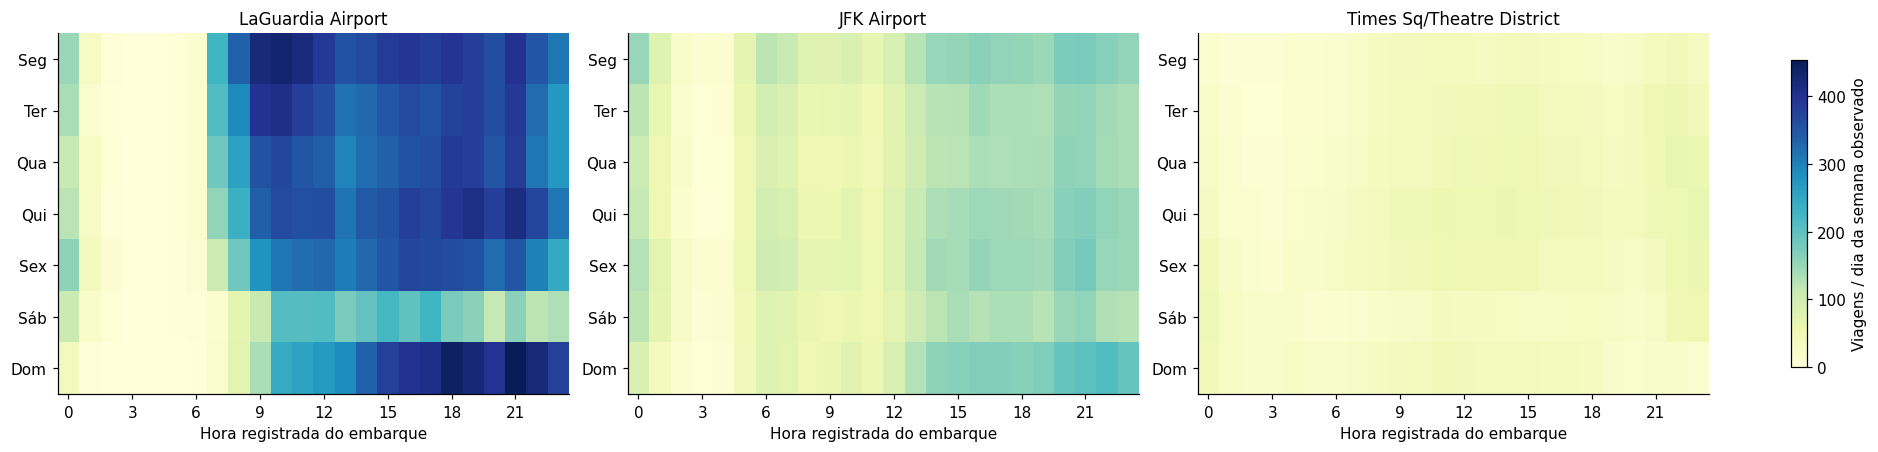

,zone_id,zone_name,weekday_name,pickup_hour,trip_count,observed_weekdays,trips_per_observed_weekday
22365,138,LaGuardia Airport,Domingo,21,23570,52,453.27
21358,132,JFK Airport,Domingo,22,10982,52,211.19
37894,230,Times Sq/Theatre District,Quarta-feira,22,3286,52,63.19


**Implicação:** essas combinações são pontos de partida para investigar movimento local. A tabela destaca um máximo por zona (em empates, o primeiro na ordem do SQL); o mapa de calor permite examinar também as faixas vizinhas. Não são recomendações de escala: faltam oferta disponível, espera, custos e validação temporal da fonte.

In [6]:
selected_hourly = hourly.loc[hourly["zone_id"].isin(candidate_zone_ids)].copy()
weekday_order = [2, 3, 4, 5, 6, 7, 1]
weekday_labels = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
color_max = selected_hourly["trips_per_observed_weekday"].max()
fig, axes = plt.subplots(1, len(candidate_zone_ids), figsize=(17, 4), constrained_layout=True, squeeze=False)

for ax, zone_id in zip(axes[0], candidate_zone_ids):
    zone_hours = selected_hourly.loc[selected_hourly["zone_id"].eq(zone_id)]
    heatmap = zone_hours.pivot(index="day_of_week", columns="pickup_hour", values="trips_per_observed_weekday")
    heatmap = heatmap.reindex(index=weekday_order, columns=range(24))
    image = ax.imshow(heatmap.to_numpy(dtype=float), aspect="auto", cmap="YlGnBu", vmin=0, vmax=color_max)
    ax.set_title(zone_hours.iloc[0]["zone_name"], fontsize=11)
    ax.set_xticks(range(0, 24, 3), range(0, 24, 3))
    ax.set_yticks(range(7), weekday_labels)
    ax.set_xlabel("Hora registrada do embarque")
fig.colorbar(image, ax=list(axes[0]), label="Viagens / dia da semana observado", shrink=0.85)
plt.show()

peak_hours = selected_hourly.loc[
    selected_hourly.groupby("zone_id")["trips_per_observed_weekday"].idxmax(),
    ["zone_id", "zone_name", "weekday_name", "pickup_hour", "trip_count", "observed_weekdays", "trips_per_observed_weekday"],
].sort_values("trips_per_observed_weekday", ascending=False)
display(peak_hours)
display(Markdown(
    "**Implicação:** essas combinações são pontos de partida para investigar movimento local. "
    "A tabela destaca um máximo por zona (em empates, o primeiro na ordem do SQL); "
    "o mapa de calor permite examinar também as faixas vizinhas. Não são recomendações de escala: "
    "faltam oferta disponível, espera, custos e validação temporal da fonte."
))

## 7. Perfil financeiro e operacional das viagens

**Pergunta:** as zonas de maior movimento apresentam perfis de viagem diferentes?

`fare_amount` é a tarifa do taxímetro; `total_amount` é o total registrado cobrado do passageiro, sem gorjetas em dinheiro. Ambos são valores históricos em USD e **não representam lucro**. Distância está em milhas e duração em minutos.

Comparamos média e mediana. Mantemos zeros, negativos e extremos; nulos são ignorados pelos agregadores SQL e os denominadores válidos são exibidos. Não calculamos uma “mediana geral” tirando média das medianas das zonas.

,zone_name,trip_count,trips_with_fare,nonpositive_fare_trips,avg_fare_usd,median_fare_usd,trips_with_total,nonpositive_total_trips,avg_total_usd,median_total_usd,avg_distance_miles,median_distance_miles,avg_duration_minutes,median_duration_minutes
0,LaGuardia Airport,1981984,1981984,529,34.12,32.50,1981984,258,46.62,45.07,10.43,10.00,35.78,31.38
1,JFK Airport,869812,869812,1685,47.73,50.50,869812,1122,57.90,58.56,16.12,16.59,42.62,37.58
2,Times Sq/Theatre District,299952,299952,978,32.73,30.50,299952,826,42.34,38.56,9.05,8.87,34.66,32.40


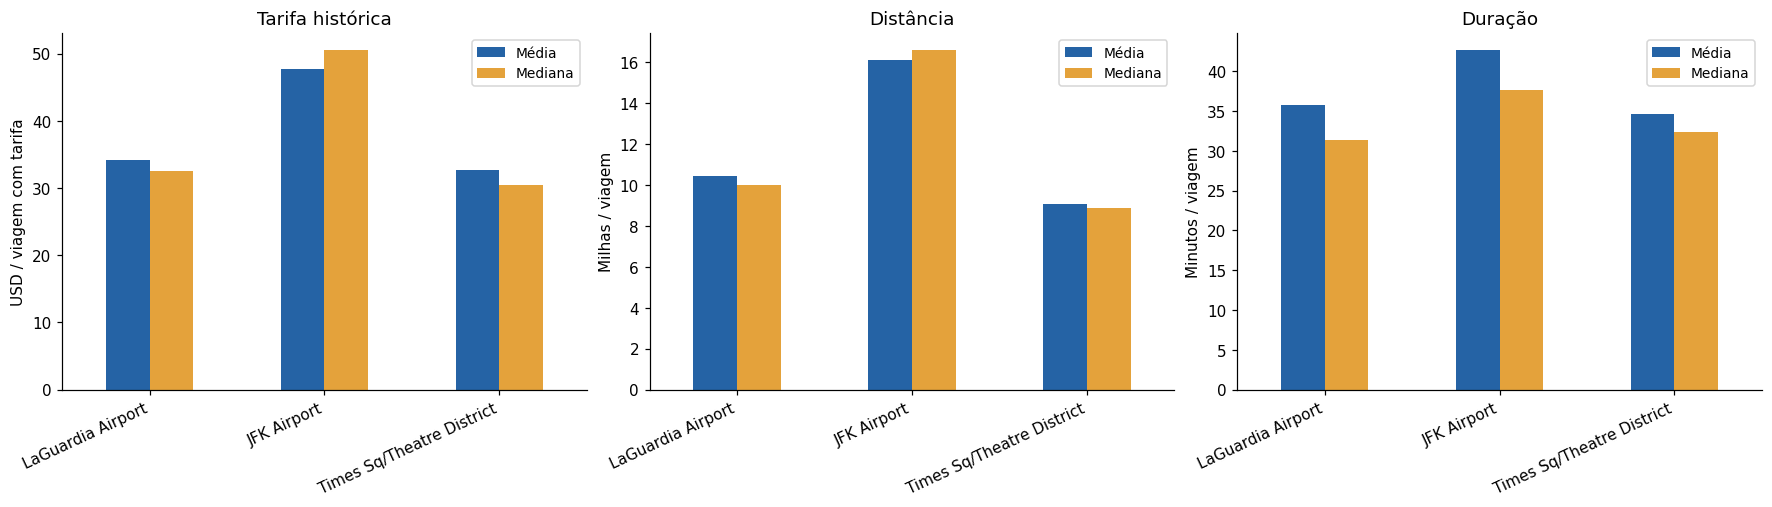

**Implicação:** diferenças de tarifa precisam ser lidas junto com distância e duração. Uma tarifa maior pode acompanhar viagens mais longas e não significar maior retorno operacional. O total cobrado inclui outros componentes e não deve ser tratado como margem. Sem custos e identificação de veículos, não estimamos lucro ou receita por táxi.

In [7]:
selected_profile = profile.loc[profile["zone_id"].isin(candidate_zone_ids)].copy()
selected_profile = selected_profile.set_index("zone_id").loc[candidate_zone_ids].reset_index()
profile_columns = [
    "zone_name", "trip_count", "trips_with_fare", "nonpositive_fare_trips",
    "avg_fare_usd", "median_fare_usd", "trips_with_total", "nonpositive_total_trips",
    "avg_total_usd", "median_total_usd", "avg_distance_miles", "median_distance_miles",
    "avg_duration_minutes", "median_duration_minutes",
]
display(selected_profile[profile_columns])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
comparisons = [
    ("avg_fare_usd", "median_fare_usd", "Tarifa histórica", "USD / viagem com tarifa"),
    ("avg_distance_miles", "median_distance_miles", "Distância", "Milhas / viagem"),
    ("avg_duration_minutes", "median_duration_minutes", "Duração", "Minutos / viagem"),
]
for ax, (mean_col, median_col, title, unit) in zip(axes, comparisons):
    selected_profile.set_index("zone_name")[[mean_col, median_col]].plot.bar(
        ax=ax, color=["#2563a5", "#e4a23b"], rot=25
    )
    ax.set(title=title, ylabel=unit, xlabel="")
    ax.legend(["Média", "Mediana"], fontsize=9)
    for label in ax.get_xticklabels():
        label.set_ha("right")
plt.show()

display(Markdown(
    "**Implicação:** diferenças de tarifa precisam ser lidas junto com distância e duração. "
    "Uma tarifa maior pode acompanhar viagens mais longas e não significar maior retorno operacional. "
    "O total cobrado inclui outros componentes e não deve ser tratado como margem. "
    "Sem custos e identificação de veículos, não estimamos lucro ou receita por táxi."
))

## 8. O destaque se mantém ao longo dos meses?

**Pergunta:** o volume e a participação das zonas selecionadas aparecem durante o ano ou ficam concentrados em meses específicos?

A média diária permite comparar meses com durações diferentes. A participação usa todas as viagens de cada mês no denominador, inclusive as de zona desconhecida. Meses sem registros permanecem visíveis: zero não comprova ausência de demanda real.

Não somamos `dataset_month_trip_count`, repetido por zona, nem percentuais mensais para obter uma participação anual.

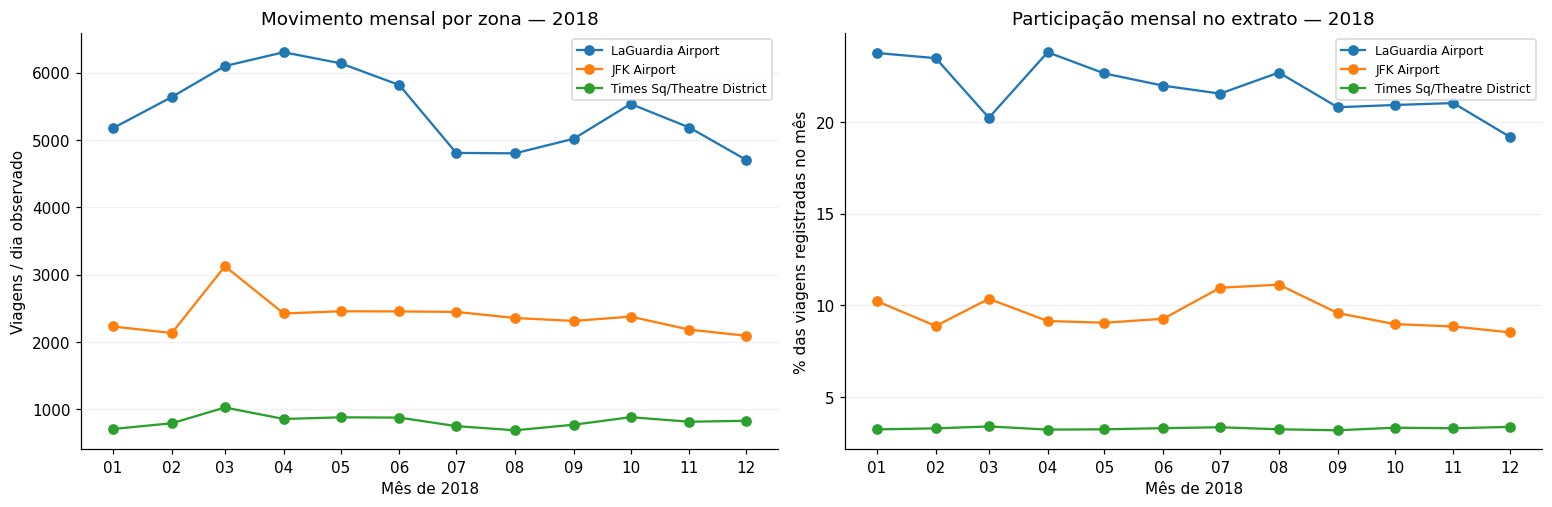

,zone_id,zone_name,months_with_trips,min_monthly_share_pct,max_monthly_share_pct,min_trips_per_day,max_trips_per_day
0,132,JFK Airport,12,8.53,11.13,"2,090.65","3,122.26"
1,138,LaGuardia Airport,12,19.18,23.80,"4,701.77","6,301.10"
2,230,Times Sq/Theatre District,12,3.19,3.40,686.68,"1,025.16"


**Leitura:** a tabela expõe presença nos meses e amplitude dos indicadores, sem classificar automaticamente uma zona como estável. Uma variação de participação pode refletir mudanças nas outras zonas ou na composição do extrato. Não é evidência isolada de mudança de demanda.

In [8]:
selected_monthly = zone_monthly.loc[zone_monthly["zone_id"].isin(candidate_zone_ids)].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for zone_id in candidate_zone_ids:
    zone_data = selected_monthly.loc[selected_monthly["zone_id"].eq(zone_id)].sort_values("month")
    name = zone_data.iloc[0]["zone_name"]
    axes[0].plot(zone_data["month"], zone_data["trips_per_observed_day"], marker="o", label=name)
    axes[1].plot(zone_data["month"], zone_data["share_of_month_dataset_pct"], marker="o", label=name)
axes[0].set(title="Movimento mensal por zona — 2018", ylabel="Viagens / dia observado")
axes[1].set(title="Participação mensal no extrato — 2018", ylabel="% das viagens registradas no mês")
for ax in axes:
    ax.set_xticks(monthly["month"], monthly["month"].dt.strftime("%m"))
    ax.set_xlabel("Mês de 2018")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.2)
plt.show()

stability = selected_monthly.groupby(["zone_id", "zone_name"], as_index=False).agg(
    months_with_trips=("trip_count", lambda values: int(values.gt(0).sum())),
    min_monthly_share_pct=("share_of_month_dataset_pct", "min"),
    max_monthly_share_pct=("share_of_month_dataset_pct", "max"),
    min_trips_per_day=("trips_per_observed_day", "min"),
    max_trips_per_day=("trips_per_observed_day", "max"),
)
display(stability)
display(Markdown(
    "**Leitura:** a tabela expõe presença nos meses e amplitude dos indicadores, sem classificar "
    "automaticamente uma zona como estável. Uma variação de participação pode refletir mudanças "
    "nas outras zonas ou na composição do extrato. Não é evidência isolada de mudança de demanda."
))

## 9. Síntese para a empresa e próximos passos

A seleção por volume serve para priorizar investigação, sem prometer viabilidade. A tabela a seguir reúne os principais indicadores das três zonas comparadas. As relações são feitas por `zone_id`, com validação de cardinalidade, sem multiplicar viagens entre grãos diferentes.

In [9]:
shortlist = top_zones.head(3)[["zone_id", "zone_name", "borough", "trip_count", "share_of_dataset_pct"]].merge(
    selected_profile[["zone_id", "median_fare_usd", "median_distance_miles", "median_duration_minutes"]],
    on="zone_id", validate="one_to_one",
).merge(
    peak_hours[["zone_id", "weekday_name", "pickup_hour", "trips_per_observed_weekday"]],
    on="zone_id", validate="one_to_one",
).merge(
    stability[["zone_id", "months_with_trips", "min_monthly_share_pct", "max_monthly_share_pct"]],
    on="zone_id", validate="one_to_one",
)
display(shortlist)

summary_lines = []
for row in shortlist.itertuples(index=False):
    summary_lines.append(
        f"- **{row.zone_name}:** {format_number(row.trip_count)} embarques "
        f"({row.share_of_dataset_pct:.2f}% do extrato); tarifa mediana USD {row.median_fare_usd:.2f}; "
        f"{row.weekday_name}, {row.pickup_hour:02d}h, é uma combinação de pico observado "
        f"({row.trips_per_observed_weekday:.2f} viagens por dia da semana observado). "
        f"Há registros em {row.months_with_trips} meses, com participação mensal entre "
        f"{row.min_monthly_share_pct:.2f}% e {row.max_monthly_share_pct:.2f}%."
    )
display(Markdown("### Evidências descritivas para investigação\n\n" + "\n".join(summary_lines)))

,zone_id,zone_name,borough,trip_count,share_of_dataset_pct,median_fare_usd,median_distance_miles,median_duration_minutes,weekday_name,pickup_hour,trips_per_observed_weekday,months_with_trips,min_monthly_share_pct,max_monthly_share_pct
0,138,LaGuardia Airport,Queens,1981984,21.78,32.50,10.00,31.38,Domingo,21,453.27,12,19.18,23.80
1,132,JFK Airport,Queens,869812,9.56,50.50,16.59,37.58,Domingo,22,211.19,12,8.53,11.13
2,230,Times Sq/Theatre District,Manhattan,299952,3.30,30.50,8.87,32.40,Quarta-feira,22,63.19,12,3.19,3.40


### Evidências descritivas para investigação

- **LaGuardia Airport:** 1.981.984 embarques (21.78% do extrato); tarifa mediana USD 32.50; Domingo, 21h, é uma combinação de pico observado (453.27 viagens por dia da semana observado). Há registros em 12 meses, com participação mensal entre 19.18% e 23.80%.
- **JFK Airport:** 869.812 embarques (9.56% do extrato); tarifa mediana USD 50.50; Domingo, 22h, é uma combinação de pico observado (211.19 viagens por dia da semana observado). Há registros em 12 meses, com participação mensal entre 8.53% e 11.13%.
- **Times Sq/Theatre District:** 299.952 embarques (3.30% do extrato); tarifa mediana USD 30.50; Quarta-feira, 22h, é uma combinação de pico observado (63.19 viagens por dia da semana observado). Há registros em 12 meses, com participação mensal entre 3.19% e 3.40%.

### Recomendação exploratória

Investigar as zonas e faixas destacadas, começando por verificar se a concentração observada reflete a composição do extrato. Comparar os aeroportos com uma zona urbana permite estudar perfis distintos, **sem concluir que operar em aeroportos seja a melhor estratégia**.

Antes de uma decisão real, precisamos confirmar a procedência e a seleção da base, o significado dos horários e a cobertura por tipo de serviço; obter dados recentes, custos, oferta concorrente e observações de campo. Falta também investigar se os padrões de dia/hora persistem mês a mês: este SQL agrega os horários do ano inteiro e a análise mensal mede volume, sem validar a estabilidade mensal do pico horário.

### Plano do dashboard em Streamlit

| Página / seção | Conteúdo | Fonte |
| --- | --- | --- |
| Contexto e qualidade | Período, viagens, zona desconhecida e limitações | Auditoria e movimento mensal |
| Movimento e zonas | Série mensal, volume por zona e borough | Consultas 01 e 02 |
| Dias e horários | Mapa de calor com seleção de zona | Consulta 03 |
| Perfil das viagens | Médias, medianas e denominadores | Consulta 04 |
| Consistência mensal | Evolução e participação por zona | Consulta 05 |

O Streamlit será a interface de apresentação em Python; o notebook mantém a investigação e sua justificativa. Na implementação futura, reutilizar os SQLs, manter as credenciais fora do código e definir atualização/cache explicitamente.

**Cuidado com filtros:** zona/hora e perfil estão agregados para 2018 inteiro. Um filtro de mês não pode alterar esses painéis usando os resultados atuais; será necessário ajustar o grão das consultas ou deixar o período anual explícito. Medianas não podem ser recalculadas a partir das medianas agregadas. A construção do app é a próxima etapa, após a revisão desta análise.

### Onde entra o Airflow?

O Airflow coordenará os scripts **Bronze → Silver → Gold → PostgreSQL**, suas dependências, logs e falhas. Ele não substitui Spark, SQL, o notebook ou o Streamlit. O app consulta a última carga confirmada no banco; a análise exploratória do notebook é revista quando necessário, sem virar uma tarefa obrigatória em cada carga.

Como este projeto usa um extrato histórico, a primeira DAG deve ter disparo manual. Agendar a mesma fonte diariamente só repetiria a carga; o agendamento será definido quando houver uma política real de atualização. Em uma rotina automática, as verificações essenciais devem permanecer nos scripts/testes, não apenas em células do notebook.

### Referências e rastreabilidade

- [README e decisões do projeto](../README.md).
- [Consultas SQL versionadas](../sql/analytics/).
- [Fonte do extrato no Kaggle](https://www.kaggle.com/datasets/neilclack/nyc-taxi-trip-data-google-public-data).
- [Dicionário TLC: distância, tarifa e total cobrado](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf).
- [Origem e limites dos dados TLC](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).

As definições das medidas seguem o dicionário, sem aplicar tarifas ou códigos de anos posteriores a 2018. Os valores apresentados correspondem à execução salva; execute **Restart Kernel → Run All** para atualizar a análise após uma nova carga. As saídas contêm agregados históricos; compartilhe-as somente quando essa divulgação for apropriada.